In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

Cell 2 – Load the dataset

In [2]:
df = pd.read_csv("emails.csv")

print("First 5 records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nStatistical Summary:")
print(df.describe())

First 5 records:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...       0.0  0.0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...       0.0  0.0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...       0.0  0.0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...       0.0  0.0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...       0.0  0.0   

   valued  lay  infrastructure  military  allowing   ff  dry  Prediction  
0     0.0  0.0             0.0       0.0       0.0  0.0  0.0         0.0  
1     0.0  0.0             0.0       0.0       0.0  1.0  0.0         0.0  
2     0.0  0.0             0.0       0.0       0.0  0.0  0.0         0.0  
3     0.0  0.0             0.0       0.0       0.0  0.0  0.0         0.0  
4     0.0  0.0             0.0       0.0       0.0  1.0  0.0         0.0  

[5 rows x 3002 columns]

Dataset Shape:
(518, 3002)

Dataset In

Cell 3 – Data preprocessing

In [3]:
# Remove unnecessary Email No. column
df.drop(columns=["Email No."], inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Remove missing values
df.dropna(inplace=True)

# Separate features and target
X = df.drop("Prediction", axis=1)

y = df["Prediction"]

print("Independent Variables Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nClass Distribution:")
print(y.value_counts())

Independent Variables Shape: (515, 3000)
Target Variable Shape: (515,)

Class Distribution:
Prediction
0.0    381
1.0    134
Name: count, dtype: int64


Cell 4 – Split dataset into training and testing sets

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (412, 3000)
Testing Data: (103, 3000)


Cell 5 – Feature scaling

In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


Cell 6 – Implement K-Nearest Neighbors (KNN)

In [6]:
# Create KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train, y_train)

# Predict results
knn_pred = knn.predict(X_test)

print("KNN Classification Completed!")

KNN Classification Completed!


Cell 7 – Implement Support Vector Machine (SVM)

In [7]:
# Create SVM model
svm = SVC(kernel="linear")

# Train the model
svm.fit(X_train, y_train)

# Predict results
svm_pred = svm.predict(X_test)

print("SVM Classification Completed!")

SVM Classification Completed!


Cell 8 – Evaluate KNN model

In [8]:
print("KNN MODEL PERFORMANCE")

print("Accuracy:",
      accuracy_score(y_test, knn_pred))

print("Precision:",
      precision_score(y_test, knn_pred))

print("Recall:",
      recall_score(y_test, knn_pred))

print("F1 Score:",
      f1_score(y_test, knn_pred))

print("\nClassification Report:")
print(classification_report(y_test, knn_pred))

KNN MODEL PERFORMANCE
Accuracy: 0.6116504854368932
Precision: 0.3968253968253968
Recall: 0.9259259259259259
F1 Score: 0.5555555555555556

Classification Report:
              precision    recall  f1-score   support

         0.0       0.95      0.50      0.66        76
         1.0       0.40      0.93      0.56        27

    accuracy                           0.61       103
   macro avg       0.67      0.71      0.61       103
weighted avg       0.80      0.61      0.63       103



Cell 9 – Evaluate SVM model

In [9]:
print("SVM MODEL PERFORMANCE")

print("Accuracy:",
      accuracy_score(y_test, svm_pred))

print("Precision:",
      precision_score(y_test, svm_pred))

print("Recall:",
      recall_score(y_test, svm_pred))

print("F1 Score:",
      f1_score(y_test, svm_pred))

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))

SVM MODEL PERFORMANCE
Accuracy: 0.883495145631068
Precision: 0.7027027027027027
Recall: 0.9629629629629629
F1 Score: 0.8125

Classification Report:
              precision    recall  f1-score   support

         0.0       0.98      0.86      0.92        76
         1.0       0.70      0.96      0.81        27

    accuracy                           0.88       103
   macro avg       0.84      0.91      0.86       103
weighted avg       0.91      0.88      0.89       103



Cell 10 – Confusion matrix for KNN

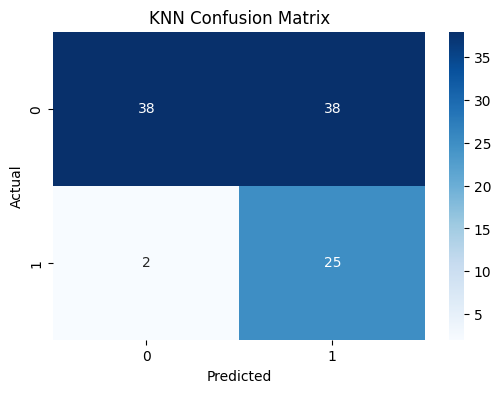

In [10]:
cm_knn = confusion_matrix(y_test, knn_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Cell 11 – Confusion matrix for SVM

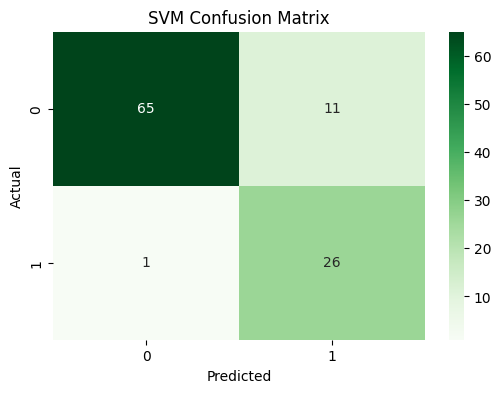

In [11]:
cm_svm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Cell 12 – Compare KNN and SVM performance

In [12]:
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],

    "Accuracy": [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ],

    "Precision": [
        precision_score(y_test, knn_pred),
        precision_score(y_test, svm_pred)
    ],

    "Recall": [
        recall_score(y_test, knn_pred),
        recall_score(y_test, svm_pred)
    ],

    "F1 Score": [
        f1_score(y_test, knn_pred),
        f1_score(y_test, svm_pred)
    ]
})

print("Model Performance Comparison:")
print(results)

# Identify the best model
best_model = results.loc[
    results["Accuracy"].idxmax(), "Model"
]

print("\nBest Performing Model:", best_model)

Model Performance Comparison:
  Model  Accuracy  Precision    Recall  F1 Score
0   KNN  0.611650   0.396825  0.925926  0.555556
1   SVM  0.883495   0.702703  0.962963  0.812500

Best Performing Model: SVM


Cell 13 – Visualize model comparison

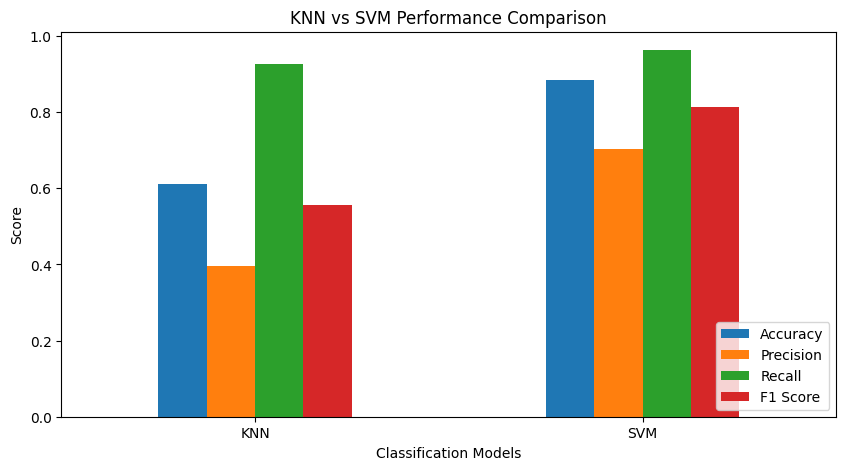

In [13]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("KNN vs SVM Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Classification Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()